# 02 — Stationarity Analysis

## Project: Improving Basket Trading Using Bayesian Optimization

### Objective
This notebook investigates the time-series properties of five U.S. sector ETFs to assess whether their price and return series exhibit evidence of stationarity.

Stationarity analysis is an important preliminary step before investigating long-run relationships and cointegration.

### Research Questions
1. Do ETF prices exhibit evidence of unit roots?
2. Are daily ETF returns more consistent with stationary behavior?
3. How do ADF and KPSS test results compare?
4. What are the implications for subsequent cointegration analysis?

### Assets
XLK, XLF, XLE, XLI, XLP

### Data Period
January 2015 – October 2026

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Project paths
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "etf_prices.csv"

# Load ETF prices
prices = pd.read_csv(
    DATA_PATH,
    index_col="Date",
    parse_dates=True
)

# Calculate daily returns
returns = prices.pct_change().dropna()

# Verify datasets
print("Prices shape:", prices.shape)
print("Returns shape:", returns.shape)

print("\nPrice date range:")
print(prices.index.min(), "to", prices.index.max())

Prices shape: (2972, 5)
Returns shape: (2971, 5)

Price date range:
2015-01-02 00:00:00 to 2026-10-27 00:00:00


## 2. Augmented Dickey-Fuller (ADF) Test
The Augmented Dickey-Fuller test is used to investigate the presence of a unit root in a time series.

### Hypotheses
- **H0:** The series contains a unit root.
- **H1:** The series is stationary around a constant under the selected model specification.

We use a significance level of 5%.

We first compare XLK price levels and daily returns to investigate how their statistical properties differ.

The ADF test is implemented with an intercept and automatic lag selection based on the Akaike Information Criterion (AIC).

In [3]:
from statsmodels.tsa.stattools import adfuller

# ADF test on XLK prices
adf_prices = adfuller(
    prices["XLK"],
    regression="c",
    autolag="AIC"
)

# ADF test on XLK daily returns
adf_returns = adfuller(
    returns["XLK"],
    regression="c",
    autolag="AIC"
)

print("ADF TEST - XLK PRICES")
print("ADF Statistic:", adf_prices[0])
print("p-value:", adf_prices[1])
print("Lags used:", adf_prices[2])

print("\nADF TEST — XLK DAILY RETURNS")
print("ADF Statistic:", adf_returns[0])
print("p-value:", adf_returns[1])
print("Lags used:", adf_returns[2])

ADF TEST — XLK PRICES
ADF Statistic: 1.6933703770972843
p-value: 0.9981123290113258
Lags used: 29

ADF TEST — XLK DAILY RETURNS
ADF Statistic: -18.492158035155043
p-value: 2.1260849237220475e-30
Lags used: 8


/var/folders/c7/tww1vnb53ssdxbfssfglvfb40000gp/T/ipykernel_30940/3155055260.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_prices = adfuller(
/var/folders/c7/tww1vnb53ssdxbfssfglvfb40000gp/T/ipykernel_30940/3155055260.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_returns = adfuller(


In [4]:
# Verify ADF results for XLK

print("XLK PRICES")
print(f"ADF Statistic: {adf_prices[0]:.6f}")
print(f"p-value: {adf_prices[1]:.12g}")
print(f"Lags used: {adf_prices[2]}")

print("\nXLK DAILY RETURNS")
print(f"ADF Statistic: {adf_returns[0]:.6f}")
print(f"p-value: {adf_returns[1]:.12g}")
print(f"Lags used: {adf_returns[2]}")

print("\nHYPOTHESIS DECISIONS")

alpha = 0.05

for name, result in [
    ("XLK Prices", adf_prices),
    ("XLK Returns", adf_returns)
]:
    if result[1] < alpha:
        print(f"{name}: Reject H0")
    else:
        print(f"{name}: Fail to reject H0")

XLK PRICES
ADF Statistic: 1.693370
p-value: 0.998112329011
Lags used: 29

XLK DAILY RETURNS
ADF Statistic: -18.492158
p-value: 2.12608492372e-30
Lags used: 8

HYPOTHESIS DECISIONS
XLK Prices: Fail to reject H0
XLK Returns: Reject H0


## 3. ADF Tests Across All ETFs

This section extends the Augmented Dickey-Fuller analysis to all five sector ETFs.

We test both price levels and daily returns using an intercept and automatic lag selection based on AIC.

The null hypothesis is that the series contains a unit root.

The significance level is set to 5%.

Results are organized into a comparative table to identify differences between price and return series.

In [8]:
# ADF tests for all ETFs

alpha = 0.05
adf_results = []

for etf in prices.columns:
    for series_type, dataset in [
        ("Prices", prices),
        ("Returns", returns)
    ]:
        result = adfuller(
        dataset[etf],
        regression="c",
        autolag="AIC",
        result_object=False
    )

        adf_results.append({
            "ETF": etf,
            "Series": series_type,
            "ADF Statistic": result[0],
            "p-value": result[1],
            "Lags": result[2],
            "Decision": (
                "Reject H0"
                if result[1] < alpha
                else "Fail to reject H0"
            )
        })

adf_df = pd.DataFrame(adf_results)

display(adf_df.round(6))

,ETF,Series,ADF Statistic,p-value,Lags,Decision
0,XLK,Prices,1.693370,0.998112,29,Fail to reject H0
1,XLK,Returns,-18.492158,0.000000,8,Reject H0
2,XLF,Prices,0.297539,0.977231,27,Fail to reject H0
3,XLF,Returns,-17.347767,0.000000,8,Reject H0
4,XLE,Prices,1.107105,0.995277,0,Fail to reject H0
5,XLE,Returns,-10.699355,0.000000,28,Reject H0
6,XLI,Prices,0.306534,0.977642,9,Fail to reject H0
7,XLI,Returns,-17.228909,0.000000,8,Reject H0
8,XLP,Prices,-0.065114,0.952804,27,Fail to reject H0
9,XLP,Returns,-11.826921,0.000000,26,Reject H0


## 4. KPSS Stationarity Test
The KPSS test complements the Augmented Dickey-Fuller test by evaluating stationarity under a different null hypothesis.

### Hypotheses
- **H0:** The series is level-stationary.
- **H1:** The series is not level-stationary.

We use a significance level of 5%.

The analysis begins with XLK prices and daily returns, using automatic lag selection.

In [9]:
from statsmodels.tsa.stattools import kpss

# KPSS test on XLK prices
kpss_prices = kpss(
    prices["XLK"],
    regression="c",
    nlags="auto"
)

# KPSS test on XLK daily returns
kpss_returns = kpss(
    returns["XLK"],
    regression="c",
    nlags="auto"
)

print("KPSS TEST — XLK PRICES")
print("KPSS Statistic:", kpss_prices[0])
print("p-value:", kpss_prices[1])
print("Lags used:", kpss_prices[2])

print("\nKPSS TEST — XLK DAILY RETURNS")
print("KPSS Statistic:", kpss_returns[0])
print("p-value:", kpss_returns[1])
print("Lags used:", kpss_returns[2])

KPSS TEST — XLK PRICES
KPSS Statistic: 7.9609560364874055
p-value: 0.01
Lags used: 32

KPSS TEST — XLK DAILY RETURNS
KPSS Statistic: 0.06817440104842971
p-value: 0.1
Lags used: 13


/var/folders/c7/tww1vnb53ssdxbfssfglvfb40000gp/T/ipykernel_30940/2526615927.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_prices = kpss(
/var/folders/c7/tww1vnb53ssdxbfssfglvfb40000gp/T/ipykernel_30940/2526615927.py:4: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_prices = kpss(
/var/folders/c7/tww1vnb53ssdxbfssfglvfb40000gp/T/ipykernel_30940/2526615927.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the

## 5. Order of Integration - First Differences

To investigate whether XLK prices are integrated of order one, I(1), we examine the first differences of the price series.

An I(1) series is non-stationary in levels but stationary after taking its first difference.

We apply both ADF and KPSS to the first-differenced XLK prices.

This analysis is distinct from testing percentage returns.

In [12]:
# Calculate first differences of ETF prices

price_diff = prices.diff().dropna()

print("Original prices shape:", prices.shape)
print("First differences shape:", price_diff.shape)

display(price_diff.head())

Original prices shape: (2972, 5)
First differences shape: (2971, 5)


,XLK,XLF,XLE,XLI,XLP
Date,,,,,
2015-01-05,-0.275398,-0.339821,-1.043102,-1.073902,-0.248840
2015-01-06,-0.214212,-0.241789,-0.355106,-0.553230,-0.043911
2015-01-07,0.148634,0.163376,0.050726,0.333557,0.600132
2015-01-08,0.389074,0.235263,0.535831,0.894932,0.541580
2015-01-09,-0.056835,-0.215662,-0.193411,-0.488152,-0.292740


In [13]:
# ADF test on XLK first differences
adf_diff = adfuller(
    price_diff["XLK"],
    regression="c",
    autolag="AIC",
    result_object=False
)

# KPSS test on XLK first differences
kpss_diff = kpss(
    price_diff["XLK"],
    regression="c",
    nlags="auto"
)

print("XLK — FIRST DIFFERENCES")

print("\nADF TEST")
print(f"ADF Statistic: {adf_diff[0]:.6f}")
print(f"p-value: {adf_diff[1]:.12g}")
print(f"Lags used: {adf_diff[2]}")

print("\nKPSS TEST")
print(f"KPSS Statistic: {kpss_diff[0]:.6f}")
print(f"p-value: {kpss_diff[1]:.12g}")
print(f"Lags used: {kpss_diff[2]}")

XLK — FIRST DIFFERENCES

ADF TEST
ADF Statistic: -9.722370
p-value: 9.46894288617e-17
Lags used: 28

KPSS TEST
KPSS Statistic: 0.485156
p-value: 0.0450099619447
Lags used: 18


/var/folders/c7/tww1vnb53ssdxbfssfglvfb40000gp/T/ipykernel_30940/3935744377.py:10: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_diff = kpss(


### XLK - Difference Test Interpretation

The ADF test strongly rejects the unit-root null hypothesis for XLK first differences (p-value approximately 9.47 × 10⁻¹⁷).
However, the KPSS test also rejects the null hypothesis of level stationarity at the 5% significance level (p-value approximately 0.0450).

These results provide mixed evidence regarding the stationarity of XLK first differences.
The KPSS result is close to the 5% threshold, suggesting that the inference is sensitive to the chosen significance level.

Therefore, the evidence is compatible with an I(1) price process, but the order of integration is not conclusively established by these tests alone.
Further diagnostics may be needed to investigate structural breaks, volatility behavior and model specification.

In [14]:
from statsmodels.tsa.stattools import adfuller, kpss
import pandas as pd
import warnings

results = []

for etf in prices.columns:
    series = price_diff[etf]

    adf = adfuller(
        series,
        regression="c",
        autolag="AIC",
        result_object=False
    )

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=Warning)
        kpss_result = kpss(
            series,
            regression="c",
            nlags="auto"
        )

    results.append({
        "ETF": etf,
        "ADF p-value": adf[1],
        "KPSS p-value": kpss_result[1],
        "ADF Decision": "Reject H0" if adf[1] < 0.05 else "Fail to reject H0",
        "KPSS Decision": "Reject H0" if kpss_result[1] < 0.05 else "Fail to reject H0"
    })

integration_df = pd.DataFrame(results)

display(integration_df.round(6))

,ETF,ADF p-value,KPSS p-value,ADF Decision,KPSS Decision
0,XLK,0.0,0.045010,Reject H0,Reject H0
1,XLF,0.0,0.100000,Reject H0,Fail to reject H0
2,XLE,0.0,0.058026,Reject H0,Fail to reject H0
3,XLI,0.0,0.100000,Reject H0,Fail to reject H0
4,XLP,0.0,0.100000,Reject H0,Fail to reject H0


In [15]:
RESULTS_PATH = PROJECT_ROOT / "results"
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

integration_df.to_csv(
    RESULTS_PATH / "integration_tests.csv",
    index=False
)

print("Integration test results saved successfully.")

Integration test results saved successfully.


## 6. Correlation Analysis

This section examines the pairwise Pearson correlations between daily ETF returns. Correlation measures the strength and direction of contemporaneous linear relationships between asset returns. Although correlation helps identify co-movement, it does not establish cointegration or a stable long-run equilibrium relationship.

,XLK,XLF,XLE,XLI,XLP
XLK,1.000,0.638,0.411,0.727,0.464
XLF,0.638,1.000,0.650,0.853,0.589
XLE,0.411,0.650,1.000,0.634,0.389
XLI,0.727,0.853,0.634,1.000,0.611
XLP,0.464,0.589,0.389,0.611,1.000


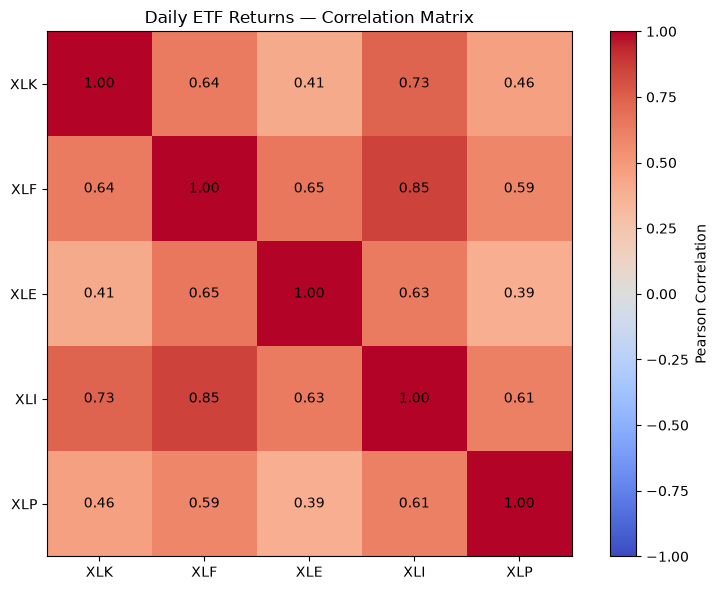

In [16]:
# Correlation matrix of daily ETF returns

correlation_matrix = returns.corr()

display(correlation_matrix.round(3))

# Plot correlation heatmap
fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_yticks(range(len(correlation_matrix.index)))

ax.set_xticklabels(correlation_matrix.columns)
ax.set_yticklabels(correlation_matrix.index)

for i in range(len(correlation_matrix)):
    for j in range(len(correlation_matrix.columns)):
        ax.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            color="black"
        )

fig.colorbar(im, ax=ax, label="Pearson Correlation")

ax.set_title("Daily ETF Returns — Correlation Matrix")

plt.tight_layout()
plt.show()

In [17]:
correlation_matrix.to_csv(
    RESULTS_PATH / "correlation_matrix.csv"
)

print("Correlation matrix saved successfully.")

Correlation matrix saved successfully.


## 7. Pairwise Cointegration Analysis

This section applies the Engle-Granger cointegration test to all possible ETF pairs.
The objective is to identify candidate pairs whose price levels may share a stationary long-run relationship.

### Hypotheses
- **H0:** The two price series are not cointegrated.
- **H1:** The two price series are cointegrated.

The significance level is set to 5%.

The analysis uses price levels rather than daily returns. Results are exploratory and will require out-of-sample validation before being used in a trading strategy.

In [18]:
from itertools import combinations
from statsmodels.tsa.stattools import coint

# Pairwise Engle-Granger cointegration tests
cointegration_results = []

for etf_1, etf_2 in combinations(prices.columns, 2):

    test_stat, p_value, critical_values = coint(
        prices[etf_1],
        prices[etf_2],
        trend="c",
        autolag="aic"
    )

    cointegration_results.append({
        "ETF 1": etf_1,
        "ETF 2": etf_2,
        "Test Statistic": test_stat,
        "p-value": p_value,
        "Cointegrated (5%)": p_value < 0.05
    })

cointegration_df = pd.DataFrame(
    cointegration_results
).sort_values("p-value")

display(cointegration_df.round(6))

,ETF 1,ETF 2,Test Statistic,p-value,Cointegrated (5%)
2,XLK,XLI,-3.599482,0.024538,True
5,XLF,XLI,-3.028793,0.103519,False
6,XLF,XLP,-2.693135,0.202057,False
1,XLK,XLE,-2.554339,0.255644,False
4,XLF,XLE,-2.271266,0.387975,False
3,XLK,XLP,-2.222034,0.413032,False
0,XLK,XLF,-2.189254,0.429912,False
9,XLI,XLP,-1.693309,0.679954,False
7,XLE,XLI,-1.313860,0.825514,False
8,XLE,XLP,-0.975676,0.907364,False


In [19]:
cointegration_df.to_csv(
    RESULTS_PATH / "cointegration_results.csv",
    index=False
)

print("Cointegration results saved successfully.")

Cointegration results saved successfully.


## 8. Preliminary Cointegration Findings

Pairwise Engle-Granger tests were conducted across all ten possible ETF pairs.

XLK–XLI produced the lowest p-value (0.024538), rejecting the null hypothesis of no cointegration at the unadjusted 5% significance level.

However, this result does not remain significant under a Bonferroni correction for ten simultaneous tests (adjusted threshold: 0.005).

The most highly correlated pair, XLF–XLI (Pearson correlation approximately 0.85), did not reject the null hypothesis of no cointegration (p-value: 0.103519).

These findings demonstrate that strong daily return correlation does not necessarily imply a stable long-run relationship between price levels.

XLK–XLI is retained as an exploratory candidate, not a confirmed trading opportunity.

The next stage will investigate multivariate cointegration using the Johansen procedure, followed by basket construction and out-of-sample evaluation.

## 9. Multivariate Cointegration - Johansen Test

The Johansen procedure is used to investigate cointegration among all five sector ETFs.

Unlike pairwise Engle-Granger testing, the Johansen approach evaluates the cointegration rank of a multivariate system.

The analysis uses ETF price levels and a constant outside the cointegration relation.

Results are exploratory and depend on the model specification, lag selection, and integration assumptions.

The objective is to identify whether a multivariate cointegration relationship may provide a baseline for subsequent basket construction.

In [20]:
from statsmodels.tsa.vector_ar.vecm import coint_johansen

# Johansen cointegration test
johansen_result = coint_johansen(
    prices,
    det_order=0,
    k_ar_diff=1
)

# Trace statistics and 95% critical values
johansen_df = pd.DataFrame({
    "Null Rank": [f"r <= {i}" for i in range(len(prices.columns))],
    "Trace Statistic": johansen_result.lr1,
    "Critical Value (95%)": johansen_result.cvt[:, 1]
})

johansen_df["Reject H0 (5%)"] = (
    johansen_df["Trace Statistic"]
    > johansen_df["Critical Value (95%)"]
)

display(johansen_df.round(4))

/Users/ady/Proyectos/bayesian-basket-trading/.venv/lib/python3.15/site-packages/statsmodels/tsa/vector_ar/vecm.py:717: ComplexWarning: Casting complex values to real discards the imaginary part
  lr1[i] = -t * np.sum(tmp, 0)
/Users/ady/Proyectos/bayesian-basket-trading/.venv/lib/python3.15/site-packages/statsmodels/tsa/vector_ar/vecm.py:718: ComplexWarning: Casting complex values to real discards the imaginary part
  lr2[i] = -t * np.log(1 - a[i])


,Null Rank,Trace Statistic,Critical Value (95%),Reject H0 (5%)
0,r <= 0,60.0922,69.8189,False
1,r <= 1,33.8444,47.8545,False
2,r <= 2,15.3244,29.7961,False
3,r <= 3,5.8984,15.4943,False
4,r <= 4,0.0120,3.8415,False


In [21]:
johansen_df.to_csv(
    RESULTS_PATH / "johansen_results.csv",
    index=False
)

print("Johansen results saved successfully.")

Johansen results saved successfully.


In [22]:
from statsmodels.tsa.vector_ar.vecm import select_order

# Select lag order for the VECM
lag_selection = select_order(
    prices,
    maxlags=10,
    deterministic="co"
)

print(lag_selection.summary())
print("\nSelected lag order (AIC):", lag_selection.selected_orders["aic"])

/Users/ady/Proyectos/bayesian-basket-trading/.venv/lib/python3.15/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/Users/ady/Proyectos/bayesian-basket-trading/.venv/lib/python3.15/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/Users/ady/Proyectos/bayesian-basket-trading/.venv/lib/python3.15/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/Users/ady/Proyectos/bayesian-basket-trading/.venv/lib/python3.15/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWar

 VECM Order Selection (* highlights the minimums) 
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -6.004     -5.933*    0.002469      -5.979
1       -6.027      -5.906    0.002413     -5.983*
2       -6.036      -5.864    0.002391      -5.974
3       -6.041      -5.818    0.002380      -5.961
4       -6.054      -5.781    0.002348      -5.956
5       -6.062      -5.738    0.002329      -5.946
6       -6.063      -5.688    0.002328      -5.928
7       -6.065      -5.640    0.002323      -5.912
8       -6.067      -5.591    0.002319      -5.895
9       -6.061      -5.535    0.002333      -5.871
10     -6.072*      -5.495   0.002306*      -5.865
--------------------------------------------------

Selected lag order (AIC): 10


/Users/ady/Proyectos/bayesian-basket-trading/.venv/lib/python3.15/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


In [23]:
from statsmodels.tsa.vector_ar.vecm import coint_johansen
import pandas as pd

sensitivity_results = []

for lag in [0, 1, 10]:

    result = coint_johansen(
        prices.to_numpy(),
        det_order=0,
        k_ar_diff=lag
    )

    trace_stat = result.lr1[0]
    critical_value = result.cvt[0, 1]

    sensitivity_results.append({
        "k_ar_diff": lag,
        "Trace Statistic (r=0)": trace_stat,
        "Critical Value (95%)": critical_value,
        "Reject H0 (5%)": trace_stat > critical_value
    })

johansen_sensitivity_df = pd.DataFrame(sensitivity_results)

display(johansen_sensitivity_df.round(4))

/Users/ady/Proyectos/bayesian-basket-trading/.venv/lib/python3.15/site-packages/statsmodels/tsa/vector_ar/vecm.py:717: ComplexWarning: Casting complex values to real discards the imaginary part
  lr1[i] = -t * np.sum(tmp, 0)
/Users/ady/Proyectos/bayesian-basket-trading/.venv/lib/python3.15/site-packages/statsmodels/tsa/vector_ar/vecm.py:718: ComplexWarning: Casting complex values to real discards the imaginary part
  lr2[i] = -t * np.log(1 - a[i])


,k_ar_diff,Trace Statistic (r=0),Critical Value (95%),Reject H0 (5%)
0,0,83.5603,69.8189,True
1,1,60.0922,69.8189,False
2,10,61.3676,69.8189,False


In [24]:
johansen_sensitivity_df.to_csv(
    RESULTS_PATH / "johansen_sensitivity.csv",
    index=False
)

print("Johansen sensitivity analysis saved successfully.")

Johansen sensitivity analysis saved successfully.


## 10. Final Findings — Stationarity and Cointegration

The analysis examined five U.S. sector ETFs using ADF, KPSS, Pearson correlation, Engle-Granger cointegration tests, and the Johansen procedure.

Price levels showed evidence consistent with non-stationary behavior, while daily percentage returns showed stronger evidence of stationarity.

First-difference tests were generally consistent with I(1) price behavior, although XLK produced mixed results under ADF and KPSS.

Pairwise Engle-Granger testing identified XLK–XLI as significant at the unadjusted 5% level, but this result did not survive correction for multiple comparisons.

Johansen cointegration results were sensitive to lag specification. The trace test rejected the null hypothesis of rank zero with zero lagged differences, but did not reject it with one or ten lagged differences.

Therefore, the analysis does not establish a robust cointegration relationship among the five ETFs.

### Implications for the Next Stage

The project will proceed with an experimental ETF basket allocation framework.

Bayesian Optimization will be used to investigate whether portfolio weights can improve a predefined risk-adjusted performance objective relative to a baseline allocation.

The strategy will not be described as a statistically validated cointegration-based mean-reversion strategy.

Out-of-sample evaluation will be required to assess whether optimization improvements generalize beyond the training data.